# Vòng 2 — Chẩn đoán dòng tiền két & phân cụm ca

**Mục tiêu**
1. Hiểu **thói quen rút tiền** của quán: sau mỗi lần chốt, két thường được để lại bao nhiêu?
2. Chấm điểm bất thường cho từng ca theo 2 cách độc lập: (a) lệch khỏi mô hình thói quen rút tiền, (b) Isolation Forest; rồi so sánh.
3. Phân cụm **hồ sơ vận hành** của ca (doanh thu, số bill, tỉ lệ tiền mặt, giá trị bill), chọn k theo cả chỉ số chất lượng lẫn **độ ổn định**.

**Input:** `data/processed_v2/shifts_v2.csv` (Vòng 1)
**Output:** `data/processed_v2/shifts_scored_v2.csv`

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

# Notebook nằm trong Final-Project/notebook-v2/ -> dữ liệu ở Final-Project/data/
ROOT = Path.cwd().resolve().parent
RAW = ROOT / 'data' / 'raw'
PROC = ROOT / 'data' / 'processed_v2'      # CSV trung gian (gitignored, có dữ liệu kinh doanh)
OUT = Path.cwd() / 'outputs'                # hình + báo cáo tổng hợp đã ẩn danh
PROC.mkdir(parents=True, exist_ok=True)
OUT.mkdir(exist_ok=True)

SEED = 42
TOL = 10_000   # tiền két được đếm tròn tới 10.000 đ -> sai số đếm ±10.000 đ

def vnd(x):
    return f"{x:,.0f} đ".replace(',', '.')

from sklearn.linear_model import HuberRegressor
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

In [2]:
shifts = pd.read_csv(PROC / 'shifts_v2.csv', parse_dates=['timestamp', 'prev_count_at'])
print(f"{len(shifts)} ca | cash_flow_gap thiếu: {shifts.cash_flow_gap.isna().sum()}")
shifts[['total_revenue', 'cash_amount', 'drawer', 'expected_drawer', 'cash_flow_gap']].describe().round(0)

236 ca | cash_flow_gap thiếu: 0


,total_revenue,cash_amount,drawer,expected_drawer,cash_flow_gap
count,236.0,236.0,236.0,236.0,236.0
mean,811419.0,426051.0,1246119.0,1670305.0,-424186.0
std,329786.0,220128.0,485990.0,539978.0,520552.0
min,87000.0,23000.0,200000.0,596000.0,-2077000.0
25%,628750.0,238500.0,890000.0,1278000.0,-731500.0
50%,782500.0,416500.0,1200000.0,1613500.0,-250000.0
75%,953000.0,566500.0,1540000.0,2006250.0,-9500.0
max,2061000.0,1058000.0,2790000.0,3509000.0,972000.0


## 1. Thói quen rút tiền: mô hình "két được để lại bao nhiêu"
Nếu chủ quán rút theo kiểu *"giữ lại một khoản tiền lẻ, rút phần dư"*, thì két sau chốt sẽ **ít phụ thuộc** vào két kỳ vọng (độ dốc nhỏ hơn 1). Ta hồi quy

$$\text{két}_t = \alpha + \beta \cdot \text{két kỳ vọng}_t + \gamma \cdot \mathbb{1}[\text{qua đêm}] + u_t$$

bằng **Huber regression** (bền với ngoại lai, vì chính các ca bất thường không được kéo lệch mô hình). Phần dư $u_t$ được chuẩn hóa bằng MAD thành **robust z-score**.

In [3]:
X_h = np.column_stack([shifts.expected_drawer / 1e6, shifts.overnight.astype(float)])
y_h = shifts.drawer / 1e6
huber = HuberRegressor(epsilon=1.35, max_iter=1000).fit(X_h, y_h)
alpha, (beta, gamma) = huber.intercept_, huber.coef_
print(f"két ≈ {alpha * 1e6:,.0f} đ + {beta:.3f} × két_kỳ_vọng {gamma * 1e6:+,.0f} đ × [qua đêm]".replace(',', '.'))
print(f"=> mỗi 1.000.000 đ tăng thêm trong két, khoảng {1 - beta:.0%} bị rút ra; két có xu hướng quay về ~{vnd(shifts.drawer.median())}")

shifts['drawer_pred'] = huber.predict(X_h) * 1e6
shifts['habit_resid'] = shifts.drawer - shifts.drawer_pred
mad = 1.4826 * np.median(np.abs(shifts.habit_resid - shifts.habit_resid.median()))
shifts['habit_z'] = (shifts.habit_resid - shifts.habit_resid.median()) / mad
print(f"MAD chuẩn hóa của phần dư: {vnd(mad)}")

Z_CUT = 3
shifts['flag_habit_low'] = shifts.habit_z < -Z_CUT
shifts['flag_habit_high'] = shifts.habit_z > Z_CUT
print(f"|z| > {Z_CUT}: thấp bất thường {shifts.flag_habit_low.sum()} ca, cao bất thường {shifts.flag_habit_high.sum()} ca")

két ≈ 482.529 đ + 0.515 × két_kỳ_vọng -174.186 đ × [qua đêm]


=> mỗi 1.000.000 đ tăng thêm trong két, khoảng 49% bị rút ra; két có xu hướng quay về ~1.200.000 đ
MAD chuẩn hóa của phần dư: 434.627 đ
|z| > 3: thấp bất thường 0 ca, cao bất thường 1 ca


**Nhận xét:** hệ số 0,515 nghĩa là cứ thêm 1 triệu đ trong két thì khoảng **một nửa bị rút ra**; két được để lại khoảng 480.000 đ + một nửa két kỳ vọng, và sau đêm thì để lại ít hơn khoảng 174.000 đ. Đây đúng là thói quen *giữ lại tiền lẻ, rút phần dư*.

Tuy nhiên độ lệch chuẩn bền (MAD) của phần dư vẫn lớn (≈ 435.000 đ): lượng tiền rút mỗi lần **rất thất thường**, nên mô hình chỉ bắt được ca lệch thật sự cực đoan. Với |z| > 3 chỉ có **1 ca** (két cao bất thường), không ca nào thấp bất thường.

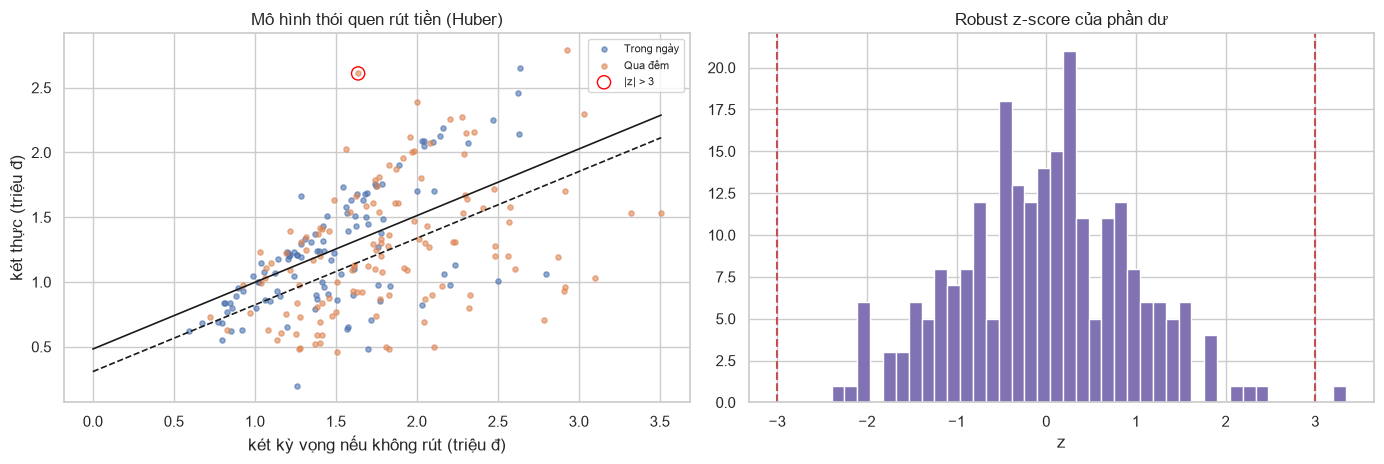

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for ov, g in shifts.groupby('overnight'):
    ax[0].scatter(g.expected_drawer / 1e6, g.drawer / 1e6, s=14, alpha=.6, label='Qua đêm' if ov else 'Trong ngày')
xs = np.linspace(0, shifts.expected_drawer.max() / 1e6, 50)
for ov, ls in [(0, '-'), (1, '--')]:
    ax[0].plot(xs, alpha + beta * xs + gamma * ov, 'k', ls=ls, lw=1.2)
flag = shifts.flag_habit_low | shifts.flag_habit_high
ax[0].scatter(shifts.loc[flag, 'expected_drawer'] / 1e6, shifts.loc[flag, 'drawer'] / 1e6, s=90, facecolors='none', edgecolors='red', label=f'|z| > {Z_CUT}')
ax[0].set_xlabel('két kỳ vọng nếu không rút (triệu đ)'); ax[0].set_ylabel('két thực (triệu đ)')
ax[0].set_title('Mô hình thói quen rút tiền (Huber)'); ax[0].legend(fontsize=8)

ax[1].hist(shifts.habit_z, bins=40, color='C4')
for v in (-Z_CUT, Z_CUT): ax[1].axvline(v, c='r', ls='--')
ax[1].set_title('Robust z-score của phần dư'); ax[1].set_xlabel('z')
plt.tight_layout(); plt.savefig(OUT / '02_withdrawal_habit.png', dpi=120); plt.show()

## 2. Ý kiến thứ hai: Isolation Forest
Dùng các biến dòng tiền và quy mô ca. Kiểm tra độ ổn định bằng cách chạy với 20 seed khác nhau.

In [5]:
IF_COLS = ['cash_flow_gap', 'drawer', 'expected_drawer', 'cash_amount', 'transfer_amount', 'bill_count']
X_if = StandardScaler().fit_transform(shifts[IF_COLS])
CONTAM = 0.05

votes = np.zeros(len(shifts))
for s in range(20):
    votes += IsolationForest(n_estimators=300, contamination=CONTAM, random_state=s).fit_predict(X_if) == -1
shifts['if_vote_rate'] = votes / 20
shifts['flag_iforest'] = shifts.if_vote_rate >= 0.5
print(f"Isolation Forest (contamination={CONTAM}): {shifts.flag_iforest.sum()} ca bị đánh dấu ở ≥ 50% số seed")
print("Phân bố tỉ lệ phiếu:", pd.cut(shifts.if_vote_rate, [-.01, 0, .25, .5, .75, 1]).value_counts().sort_index().to_dict())

agree = pd.crosstab(shifts.flag_iforest, shifts.flag_habit_low | shifts.flag_habit_high,
                    rownames=['Isolation Forest'], colnames=['Mô hình thói quen |z|>3'])
display(agree)

Isolation Forest (contamination=0.05): 13 ca bị đánh dấu ở ≥ 50% số seed
Phân bố tỉ lệ phiếu: {Interval(-0.01, 0.0, closed='right'): 221, Interval(0.0, 0.25, closed='right'): 1, Interval(0.25, 0.5, closed='right'): 1, Interval(0.5, 0.75, closed='right'): 3, Interval(0.75, 1.0, closed='right'): 10}


Mô hình thói quen |z|>3,False,True
Isolation Forest,,
False,223,0
True,12,1


**Nhận xét:** Isolation Forest ổn định (hầu hết ca có tỉ lệ phiếu 0% hoặc ≥ 75%), đánh dấu 13 ca. Nhưng chỉ **1 ca** trùng với mô hình thói quen rút tiền.

In [6]:
show = ['timestamp', 'shift', 'cash_amount', 'expected_drawer', 'drawer', 'cash_flow_gap', 'habit_z', 'if_vote_rate']
anom = shifts[shifts.flag_iforest | shifts.flag_habit_low | shifts.flag_habit_high][show].sort_values('habit_z')
display(anom.style.format({'cash_amount': vnd, 'expected_drawer': vnd, 'drawer': vnd, 'cash_flow_gap': vnd,
                           'habit_z': '{:+.2f}', 'if_vote_rate': '{:.0%}'}))

,timestamp,shift,cash_amount,expected_drawer,drawer,cash_flow_gap,habit_z,if_vote_rate
179,2026-04-01 18:00:10,Chiều,715.000 đ,2.105.000 đ,500.000 đ,-1.605.000 đ,-2.07,100%
120,2026-02-26 18:02:11,Chiều,983.000 đ,3.103.000 đ,1.030.000 đ,-2.073.000 đ,-2.03,100%
209,2026-04-17 17:31:20,Chiều,860.000 đ,1.810.000 đ,500.000 đ,-1.310.000 đ,-1.72,100%
159,2026-03-20 18:01:49,Chiều,971.000 đ,2.331.000 đ,900.000 đ,-1.431.000 đ,-1.42,100%
53,2026-01-16 17:22:22,Chiều,679.000 đ,2.869.000 đ,1.190.000 đ,-1.679.000 đ,-1.39,100%
134,2026-03-06 11:57:21,Sáng,859.000 đ,3.509.000 đ,1.530.000 đ,-1.979.000 đ,-1.36,100%
124,2026-03-01 11:54:30,Sáng,533.000 đ,3.323.000 đ,1.530.000 đ,-1.793.000 đ,-1.14,55%
158,2026-03-19 19:19:34,Chiều,941.000 đ,1.831.000 đ,1.360.000 đ,-471.000 đ,+0.23,95%
166,2026-03-24 17:37:55,Chiều,1.006.000 đ,1.866.000 đ,1.610.000 đ,-256.000 đ,+0.77,100%
227,2026-04-26 15:37:56,Chiều,47.000 đ,2.047.000 đ,2.050.000 đ,3.000 đ,+1.17,55%


**Nhận xét:** đa số ca Isolation Forest đánh dấu là ca **tiền mặt lớn, két kỳ vọng cao rồi bị rút mạnh**. Đó là ca *đông khách*, không phải ca *đáng ngờ*: Isolation Forest bắt quy mô bất thường chứ không bắt hành vi bất thường. Vì vậy Vòng 4 **không dùng Isolation Forest làm luật cảnh báo**, chỉ dùng mô hình thói quen rút tiền và dấu của `cash_flow_gap`, vì hai thứ này có diễn giải nghiệp vụ rõ ràng.

## 3. Phân cụm hồ sơ vận hành của ca
Mục đích là **mô tả** các kiểu ca (không dùng để kết luận gian lận). Biến dùng: log doanh thu, số bill, tỉ lệ tiền mặt, giá trị bill trung bình. **Không** đưa vào biến hằng (`Payment_Mismatch` = 0 ở mọi ca) hay biến dòng tiền két (đã chứa tiền rút không ghi nhận).

Chọn k theo 2 tiêu chí:
- **Chất lượng:** Silhouette ↑, Davies-Bouldin ↓, Calinski-Harabasz ↑.
- **Độ ổn định:** lấy mẫu bootstrap 50 lần, phân cụm lại, so với phân cụm gốc bằng ARI. Cụm chỉ đáng diễn giải khi ARI trung bình ≥ 0.75.

In [7]:
shifts['log_revenue'] = np.log(shifts.total_revenue)
shifts['cash_ratio'] = shifts.cash_amount / shifts.total_revenue
shifts['avg_bill'] = shifts.total_revenue / shifts.bill_count
CL_COLS = ['log_revenue', 'bill_count', 'cash_ratio', 'avg_bill']
X_cl = StandardScaler().fit_transform(shifts[CL_COLS])
display(shifts[CL_COLS].corr().round(2))

rng = np.random.default_rng(SEED)
rows = []
for k in range(2, 9):
    ref = KMeans(k, n_init=20, random_state=SEED).fit(X_cl)
    aris = []
    for _ in range(50):
        idx = rng.choice(len(X_cl), len(X_cl), replace=True)
        km = KMeans(k, n_init=10, random_state=int(rng.integers(1e6))).fit(X_cl[idx])
        aris.append(adjusted_rand_score(ref.labels_, km.predict(X_cl)))
    rows.append(dict(k=k, inertia=ref.inertia_, silhouette=silhouette_score(X_cl, ref.labels_),
                     davies_bouldin=davies_bouldin_score(X_cl, ref.labels_),
                     calinski_harabasz=calinski_harabasz_score(X_cl, ref.labels_),
                     stability_ari=np.mean(aris), stability_sd=np.std(aris),
                     min_cluster=np.bincount(ref.labels_).min()))
ksel = pd.DataFrame(rows).set_index('k')
display(ksel.round(3))

,log_revenue,bill_count,cash_ratio,avg_bill
log_revenue,1.00,0.86,0.13,0.13
bill_count,0.86,1.00,0.19,-0.26
cash_ratio,0.13,0.19,1.00,-0.10
avg_bill,0.13,-0.26,-0.10,1.00


,inertia,silhouette,davies_bouldin,calinski_harabasz,stability_ari,stability_sd,min_cluster
k,,,,,,,
2,665.191,0.285,1.348,98.079,0.803,0.138,114
3,536.066,0.299,1.234,88.654,0.672,0.168,38
4,433.799,0.299,1.071,90.953,0.689,0.189,25
5,357.906,0.303,1.048,94.569,0.776,0.111,23
6,320.620,0.296,1.066,89.438,0.681,0.142,7
7,287.592,0.293,1.029,87.113,0.643,0.130,7
8,265.169,0.248,1.050,83.383,0.513,0.092,6


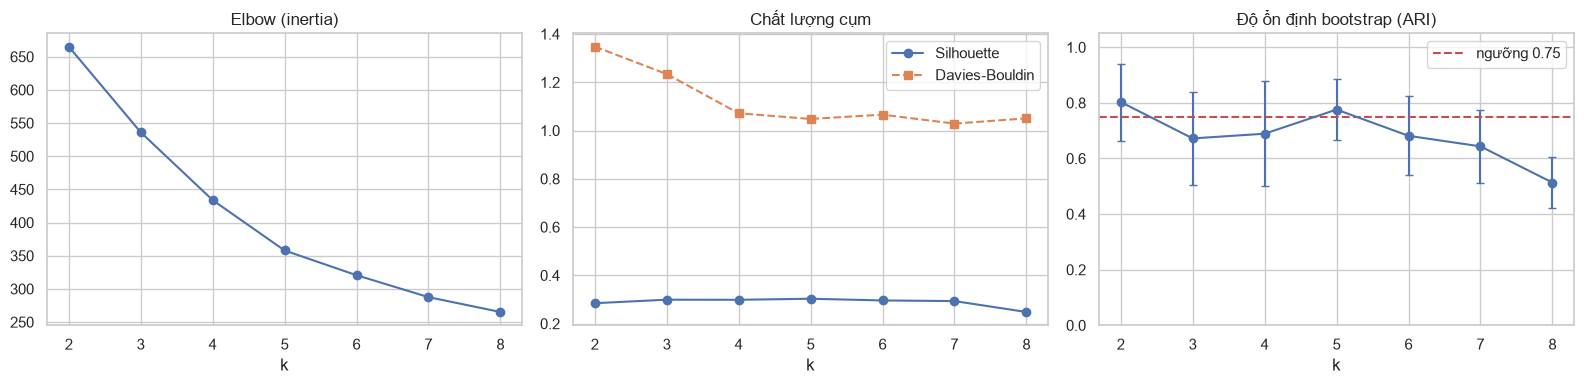

Các k đạt ổn định ≥ 0.75 và cụm nhỏ nhất ≥ 10 ca: [2, 5]
=> Chọn k = 5 (Silhouette cao nhất trong nhóm ổn định)


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(ksel.index, ksel.inertia, 'o-'); ax[0].set_title('Elbow (inertia)')
ax[1].plot(ksel.index, ksel.silhouette, 'o-', label='Silhouette')
ax[1].plot(ksel.index, ksel.davies_bouldin, 's--', label='Davies-Bouldin'); ax[1].legend(); ax[1].set_title('Chất lượng cụm')
ax[2].errorbar(ksel.index, ksel.stability_ari, yerr=ksel.stability_sd, fmt='o-', capsize=3)
ax[2].axhline(0.75, c='r', ls='--', label='ngưỡng 0.75'); ax[2].set_ylim(0, 1.05); ax[2].legend()
ax[2].set_title('Độ ổn định bootstrap (ARI)')
for a in ax: a.set_xlabel('k')
plt.tight_layout(); plt.savefig(OUT / '02_choose_k.png', dpi=120); plt.show()

stable = ksel[(ksel.stability_ari >= 0.75) & (ksel.min_cluster >= 10)]
K = int(stable.silhouette.idxmax()) if len(stable) else int(ksel.silhouette.idxmax())
print("Các k đạt ổn định ≥ 0.75 và cụm nhỏ nhất ≥ 10 ca:", list(stable.index))
print(f"=> Chọn k = {K} (Silhouette cao nhất trong nhóm ổn định)")

**Nhận xét:** mọi k đều có Silhouette chỉ ≈ 0,25–0,30, tức là **cấu trúc cụm yếu**: các ca nằm trên một dải liên tục chứ không tách thành nhóm rõ ràng. Chỉ k = 2 và k = 5 vượt ngưỡng ổn định 0,75 với cụm nhỏ nhất ≥ 10 ca. Chọn **k = 5** vì Silhouette cao hơn và cho mô tả chi tiết hơn. Bản v1 chọn k = 4, nhưng ở dữ liệu này k = 4 kém ổn định (ARI bootstrap 0,69).

In [9]:
km = KMeans(K, n_init=50, random_state=SEED).fit(X_cl)
order = pd.Series(km.labels_).groupby(km.labels_).apply(lambda s: shifts.loc[s.index, 'total_revenue'].mean()).sort_values().index
remap = {old: new for new, old in enumerate(order)}
shifts['cluster'] = pd.Series(km.labels_).map(remap)

ward = AgglomerativeClustering(K, linkage='ward').fit_predict(X_cl)
gmm = GaussianMixture(K, n_init=10, random_state=SEED).fit(X_cl).predict(X_cl)
print(f"Đồng thuận với K-Means (ARI): Ward = {adjusted_rand_score(shifts.cluster, ward):.3f} | GMM = {adjusted_rand_score(shifts.cluster, gmm):.3f}")

profile = shifts.groupby('cluster').agg(
    so_ca=('cluster', 'size'), ty_le_ca_sang=('shift', lambda s: (s == 'Sáng').mean()),
    doanh_thu_tb=('total_revenue', 'mean'), so_bill_tb=('bill_count', 'mean'),
    ty_le_tien_mat=('cash_ratio', 'mean'), gia_tri_bill_tb=('avg_bill', 'mean'),
    gap_trung_vi=('cash_flow_gap', 'median'),
    ca_bat_thuong=('flag_iforest', 'sum'))
display(profile.style.format({'ty_le_ca_sang': '{:.0%}', 'doanh_thu_tb': vnd, 'so_bill_tb': '{:.1f}',
                              'ty_le_tien_mat': '{:.0%}', 'gia_tri_bill_tb': vnd, 'gap_trung_vi': vnd}))

Đồng thuận với K-Means (ARI): Ward = 0.674 | GMM = 0.451


,so_ca,ty_le_ca_sang,doanh_thu_tb,so_bill_tb,ty_le_tien_mat,gia_tri_bill_tb,gap_trung_vi,ca_bat_thuong
cluster,,,,,,,,
0,27,4%,331.000 đ,10.9,49%,30.827 đ,-52.000 đ,1
1,23,70%,682.783 đ,13.5,60%,51.565 đ,-146.000 đ,0
2,72,4%,714.444 đ,19.8,36%,36.431 đ,-140.000 đ,0
3,88,85%,875.557 đ,26.6,63%,33.221 đ,-560.000 đ,3
4,26,54%,1.475.577 đ,40.1,53%,37.416 đ,-600.500 đ,9


**Nhận xét (đặt tên cụm theo hồ sơ):**

| Cụm | Mô tả | Ghi chú |
|---|---|---|
| 0 | Ca chiều vắng (~331k, 11 bill) | gần như toàn ca chiều |
| 1 | Ca bill giá trị cao (~52k/bill) | chủ yếu ca sáng |
| 2 | Ca chiều thường, ít tiền mặt (36%) | |
| 3 | Ca sáng đông (~27 bill, 63% tiền mặt) | rút tiền nhiều nhất (trung vị −560k) |
| 4 | Ca rất đông (~1,5 triệu, 40 bill) | 9/13 ca Isolation Forest nằm ở đây |

Cụm chủ yếu tách theo **ca sáng/chiều và quy mô**. Đồng thuận với Ward (ARI 0,67) và GMM (0,45) ở mức trung bình, nên ranh giới cụm chỉ mang tính mô tả.

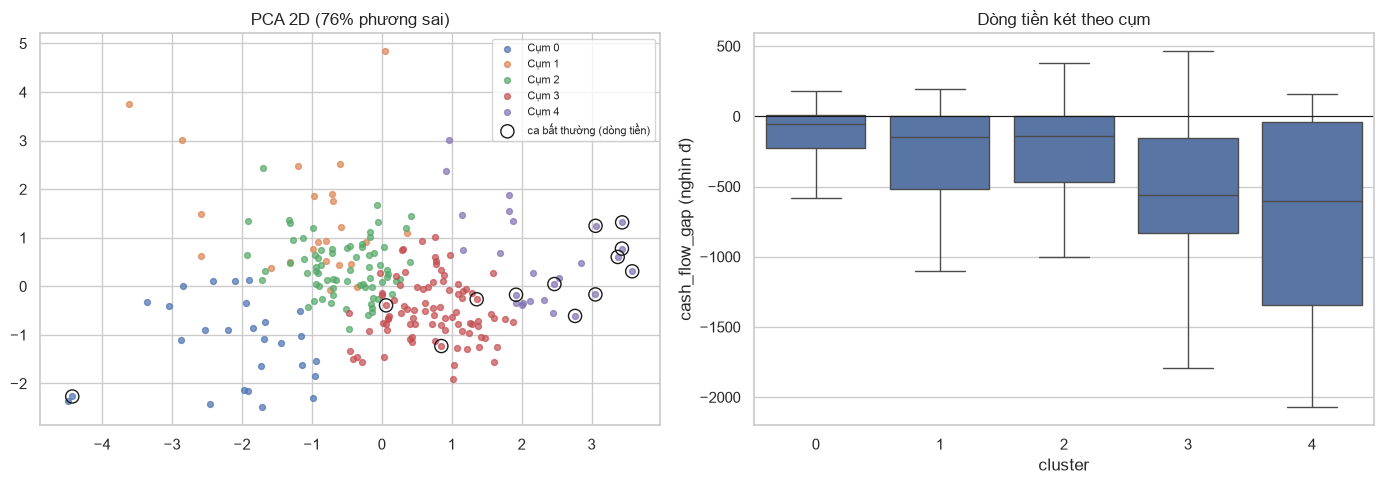

In [10]:
pc = PCA(2, random_state=SEED).fit(X_cl)
P = pc.transform(X_cl)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for c in sorted(shifts.cluster.unique()):
    m = shifts.cluster == c
    ax[0].scatter(P[m, 0], P[m, 1], s=18, alpha=.7, label=f'Cụm {c}')
m = shifts.flag_iforest | shifts.flag_habit_low | shifts.flag_habit_high
ax[0].scatter(P[m, 0], P[m, 1], s=90, facecolors='none', edgecolors='k', label='ca bất thường (dòng tiền)')
ax[0].set_title(f'PCA 2D ({pc.explained_variance_ratio_.sum():.0%} phương sai)'); ax[0].legend(fontsize=8)

sns.boxplot(data=shifts, x='cluster', y=shifts.cash_flow_gap / 1e3, ax=ax[1], showfliers=False)
ax[1].axhline(0, c='k', lw=.8); ax[1].set_ylabel('cash_flow_gap (nghìn đ)'); ax[1].set_title('Dòng tiền két theo cụm')
plt.tight_layout(); plt.savefig(OUT / '02_clusters.png', dpi=120); plt.show()

## 4. Lưu kết quả

In [11]:
keep = ['shift_id', 'drawer_pred', 'habit_resid', 'habit_z', 'flag_habit_low', 'flag_habit_high',
        'if_vote_rate', 'flag_iforest', 'log_revenue', 'cash_ratio', 'avg_bill', 'cluster']
out = shifts.drop(columns=[c for c in keep if c != 'shift_id']).merge(shifts[keep], on='shift_id')
out.to_csv(PROC / 'shifts_scored_v2.csv', index=False)
ksel.round(4).to_csv(OUT / '02_k_selection.csv')
print(f"Đã lưu {len(out)} ca -> {PROC / 'shifts_scored_v2.csv'}")

Đã lưu 236 ca -> D:\Data Analysis\Data-Mining\Final-Project\data\processed_v2\shifts_scored_v2.csv


## ✅ Tổng kết Vòng 2
- **Thói quen rút tiền:** két được giữ quanh 1,2 triệu đ, khoảng một nửa phần tăng thêm bị rút ra; lượng rút rất thất thường nên chỉ 1 ca lệch hẳn khỏi thói quen (|z| > 3).
- **Isolation Forest** bắt quy mô (ca đông) chứ không bắt hành vi → không dùng làm luật.
- **Phân cụm** (k = 5, ổn định bootstrap 0,78) chỉ mô tả các kiểu ca theo thời điểm và quy mô; cấu trúc cụm yếu (Silhouette ≈ 0,30), không dùng để kết luận rủi ro.